In [35]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score
import xgb_utils
import numpy as np
import pandas as pd
import math
import pickle as pickle
import os
import shutil
import uproot
import sys
import optuna
import optuna.visualization as vis
import matplotlib.pyplot as plt
import mplhep as hep
import plotly.io as pio
from plotly.io import show

pio.renderers.default = "notebook"
%matplotlib inline

In [2]:
channel_US, era = "ggH", "Combined"
background_subset = "Full"
signal_subset = "NottH"
SIGNAL_REGION = (121, 129)
plot_dir = "BDTplots/"

variables = xgb_utils.get_variables(channel_US, True)
print("number of variables", len(variables) - 3)
print(variables)

number of variables 18
[['diMuon_rapidity', 'diMuon_rapidity', '$y_{\\mu\\mu}$'], ['mu1_eta', 'mu1_eta', '$\\eta_{\\mu 1}$'], ['mu2_eta', 'mu2_eta', '$\\eta_{\\mu 2}$'], ['phi_CS', 'phi_CS', '$\\phi_{CS}$'], ['cos_theta_CS', 'cos_theta_CS', '$cos(\\theta_{CS})$'], ['n_jet', 'n_jet', '$N_{jets}$'], ['leading_jet_pt', 'leading_jet_pt', '$p_T^{j1}$'], ['leading_jet_eta', 'leading_jet_eta', '$\\eta_{j1}$'], ['subleading_jet_pt', 'subleading_jet_pt', '$p_T^{j2}$ [GeV]'], ['diJet_mass', 'diJet_mass', '$m_{jj}$ [GeV]'], ['delta_eta_diJet', 'delta_eta_diJet', '$\\Delta\\eta_{jj}$'], ['delta_phi_diJet', 'delta_phi_diJet', '$\\Delta\\phi_{jj}$ [rad]'], ['z_zeppenfeld', 'z_zeppenfeld', '$Z^{*} Zeppendfeld$'], ['min_delta_eta_diMuon_jet', 'min_delta_eta_diMuon_jet', 'min$|\\Delta\\eta_{\\mu\\mu,j}|$'], ['min_delta_phi_diMuon_jet', 'min_delta_phi_diMuon_jet', 'min$|\\Delta\\phi_{\\mu\\mu,j}|$ [rad]'], ['diMuon_bsConstrainedPt', 'diMuon_bsConstrainedPt', '$p_T^{\\mu\\mu}$ [GeV] (bsC)'], ['mu1_bsCons

In [3]:
test_name = f"{channel_US}_{era}_B{background_subset}_S{signal_subset}"
plot_path = f"../../plots/xgboost/{channel_US}/B{background_subset}_S{signal_subset}/"
data_directory = f"../../root_io/skim/{channel_US}/"
signal_file_name = f"{data_directory}signal_{era}_skim_{signal_subset}.root"
bkg_file_name = f"{data_directory}background_{era}_skim_{background_subset}.root"

print("[INFO]: Creating data frames")
with uproot.open(signal_file_name) as file:
    df_signal = pd.DataFrame(
        file["tree_output"].arrays([var[0] for var in variables], library="np"),
    )
with uproot.open(bkg_file_name) as file:
    df_bkg = pd.DataFrame(
        file["tree_output"].arrays([var[0] for var in variables], library="np"),
    )
print("[INFO]: Data frames created successfully")

[INFO]: Creating data frames
[INFO]: Data frames created successfully


In [4]:
##DOES THIS MAKE SENSE TO DO??
mass_var_name = "diMuon_bsConstrainedMass"
bkg_events = df_bkg["weight"][
    (df_bkg[mass_var_name] > SIGNAL_REGION[0])
    & (df_bkg[mass_var_name] < SIGNAL_REGION[1])
].sum()
signal_events = df_signal["weight"][
    (df_signal[mass_var_name] > SIGNAL_REGION[0])
    & (df_signal[mass_var_name] < SIGNAL_REGION[1])
].sum()

print("Bkg events: " + str(bkg_events))
print("Sig events: " + str(signal_events))

Bkg events: 519289.35904562974
Sig events: 1231.2887177289617


In [5]:
df_signal

,diMuon_rapidity,mu1_eta,mu2_eta,phi_CS,cos_theta_CS,n_jet,leading_jet_pt,leading_jet_eta,subleading_jet_pt,diJet_mass,...,delta_phi_diJet,z_zeppenfeld,min_delta_eta_diMuon_jet,min_delta_phi_diMuon_jet,diMuon_bsConstrainedPt,mu1_bsConstrainedPt_mass_ratio,mu2_bsConstrainedPt_mass_ratio,diMuon_bsConstrainedMass,relative_diMuon_bsConstrainedMass_error,weight
0,NaN,-0.182556,1.756592,0.770020,-0.696167,1,28.609375,-1.828613,0.0,0.0,...,-1.0,0.0,3.175293,-3.126953,43.171875,0.464233,0.255066,124.156250,0.019493,0.000740
1,0.562134,0.820923,1.291016,-0.691162,-0.075851,1,35.656250,3.854492,0.0,0.0,...,-1.0,0.0,1.763184,2.910645,38.109375,0.627930,0.392395,122.625000,0.020172,0.000427
2,-1.270508,0.460205,0.957397,2.646973,0.185303,0,0.000000,0.000000,0.0,0.0,...,-1.0,0.0,0.000000,0.000000,17.507812,0.550537,0.429077,126.609375,0.020821,0.000306
3,0.678833,1.788330,1.817627,2.774414,-0.109497,0,0.000000,0.000000,0.0,0.0,...,-1.0,0.0,0.000000,0.000000,18.101562,0.572754,0.437622,124.984375,0.028473,0.000166
4,-0.354370,-0.417419,1.156982,0.385925,-0.613892,1,42.000000,0.247284,0.0,0.0,...,-1.0,0.0,0.161194,2.802734,41.562500,0.556152,0.259766,128.906250,0.017632,0.000746
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4151240,-1.845215,-0.642334,0.505737,-1.674561,0.620361,1,91.125000,-3.287598,0.0,0.0,...,-1.0,0.0,3.084473,-2.927246,82.093750,0.551392,0.470215,126.000000,0.016888,0.000021
4151241,-0.111496,-0.569702,2.002441,0.470032,-0.899414,1,69.750000,3.408691,0.0,0.0,...,-1.0,0.0,2.855957,3.114258,76.187500,0.479980,0.176910,123.609375,0.024746,0.000024
4151242,1.003418,1.712646,0.306946,1.697266,-0.766357,1,62.125000,3.289062,0.0,0.0,...,-1.0,0.0,1.499268,-3.005859,75.812500,0.617188,0.328308,125.484375,0.021717,0.000034
4151243,1.198975,1.900391,-0.728882,-0.217926,0.875977,1,33.500000,3.735840,0.0,0.0,...,-1.0,0.0,0.370239,-3.020020,6.319336,0.276672,0.226837,124.234375,0.026028,0.000034


In [6]:
df_bkg

,diMuon_rapidity,mu1_eta,mu2_eta,phi_CS,cos_theta_CS,n_jet,leading_jet_pt,leading_jet_eta,subleading_jet_pt,diJet_mass,...,delta_phi_diJet,z_zeppenfeld,min_delta_eta_diMuon_jet,min_delta_phi_diMuon_jet,diMuon_bsConstrainedPt,mu1_bsConstrainedPt_mass_ratio,mu2_bsConstrainedPt_mass_ratio,diMuon_bsConstrainedMass,relative_diMuon_bsConstrainedMass_error,weight
0,NaN,-1.143311,-2.119141,2.889648,-0.418152,1,25.265625,3.816895,0.0,0.0,...,-1.0,0.0,8.500000,0.784058,5.037109,0.466736,0.425964,119.125000,0.037178,2.118659
1,-1.098389,1.745850,0.544556,-1.937256,-0.600098,0,0.000000,0.000000,0.0,0.0,...,-1.0,0.0,0.000000,0.000000,25.847656,0.480774,0.383850,118.609375,0.023506,10.447008
2,-0.441528,-0.545044,-0.411804,0.051117,-0.083298,0,0.000000,0.000000,0.0,0.0,...,-1.0,0.0,0.000000,0.000000,5.516602,0.522583,0.476318,119.140625,0.014294,3.462130
3,-0.481567,0.054016,-2.016602,0.812866,0.744263,0,0.000000,0.000000,0.0,0.0,...,-1.0,0.0,0.000000,0.000000,14.646484,0.357788,0.280579,117.093750,0.023464,1.921823
4,-1.105469,-1.227539,0.806519,0.852905,-0.773193,0,0.000000,0.000000,0.0,0.0,...,-1.0,0.0,0.000000,0.000000,6.469727,0.338623,0.302551,117.718750,0.020168,6.528768
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11279209,-1.830322,0.413452,-0.084412,0.714478,0.312927,1,71.687500,1.221924,0.0,0.0,...,-1.0,0.0,0.706787,-3.006348,68.562500,0.763794,0.346863,125.078125,0.014317,0.008942
11279210,0.406189,0.110046,0.377441,-0.291138,-0.027397,0,0.000000,0.000000,0.0,0.0,...,-1.0,0.0,0.000000,0.000000,103.984375,1.029541,0.251709,127.984375,0.017632,0.008514
11279211,-0.260498,0.871826,-2.090332,-0.077194,0.976318,1,63.500000,0.413879,0.0,0.0,...,-1.0,0.0,1.462402,2.907227,56.257812,0.265869,0.216156,116.781250,0.027073,0.013837
11279212,-1.645508,-1.251709,0.537598,-1.602783,0.916992,1,62.500000,-0.001029,0.0,0.0,...,-1.0,0.0,0.928345,-2.413086,107.890625,0.661865,0.291809,127.921875,0.019707,0.007409


In [7]:
signal_weight_sum = df_signal["weight"].sum()
bkg_weight_sum = df_bkg["weight"].sum()
print("Sig weight initial: " + str(signal_weight_sum))
print("Bkg weight initial: " + str(bkg_weight_sum))

df_signal["weight"] = df_signal["weight"] * (bkg_weight_sum / signal_weight_sum)

signal_weight_sum = df_signal["weight"].sum()
bkg_weight_sum = df_bkg["weight"].sum()
print("Sig weight post: " + str(signal_weight_sum))
print("Bkg weight post: " + str(bkg_weight_sum))

Sig weight initial: 1339.6980682420763
Bkg weight initial: 1390626.5100010727
Sig weight post: 1390626.510001073
Bkg weight post: 1390626.5100010727


In [8]:
s_over_sqrt_b = signal_events / math.sqrt(bkg_events)
print(
    f"[INFO]: S = {signal_events:.3f}; B = {bkg_events:.3f}; S/sqrt(B) = {s_over_sqrt_b:.3f}"
)
print(f"[INFO]: Signal sample size: {len(df_signal.values)}")
print(f"[INFO]: Bkg sample size: {len(df_bkg.values)}")

[INFO]: S = 1231.289; B = 519289.359; S/sqrt(B) = 1.709
[INFO]: Signal sample size: 4151245
[INFO]: Bkg sample size: 11279214


In [9]:
x = np.concatenate([df_bkg.values, df_signal.values])
y = np.concatenate([np.zeros(len(df_bkg)), np.ones(len(df_signal))])

In [10]:
x

array([[            nan, -1.14331055e+00, -2.11914062e+00, ...,
         1.19125000e+02,  3.71780396e-02,  2.11865878e+00],
       [-1.09838867e+00,  1.74584961e+00,  5.44555664e-01, ...,
         1.18609375e+02,  2.35061646e-02,  1.04470081e+01],
       [-4.41528320e-01, -5.45043945e-01, -4.11804199e-01, ...,
         1.19140625e+02,  1.42936707e-02,  3.46213007e+00],
       ...,
       [ 1.00341797e+00,  1.71264648e+00,  3.06945801e-01, ...,
         1.25484375e+02,  2.17170715e-02,  3.49716019e-02],
       [ 1.19897461e+00,  1.90039062e+00, -7.28881836e-01, ...,
         1.24234375e+02,  2.60276794e-02,  3.49716019e-02],
       [ 1.20947266e+00,  2.93212891e-01,  5.62667847e-03, ...,
         1.25640625e+02,  1.51596069e-02,  3.80933171e-02]],
      shape=(15430459, 21))

In [11]:
y

array([0., 0., 0., ..., 1., 1., 1.], shape=(15430459,))

In [24]:
SEED = 7
TEST_SIZE = 0.4
SAMPLE_SIZE = 1.0
x_train_p, x_test_p, y_train, y_test = train_test_split(
    x,
    y,
    train_size=SAMPLE_SIZE * (1 - TEST_SIZE),
    test_size=SAMPLE_SIZE * TEST_SIZE,
    random_state=SEED,
)

In [25]:
x_train = x_train_p[:, :-3]
x_test = x_test_p[:, :-3]
sample_weights_train = x_train_p[:, -1]
sample_weights_test = x_test_p[:, -1]

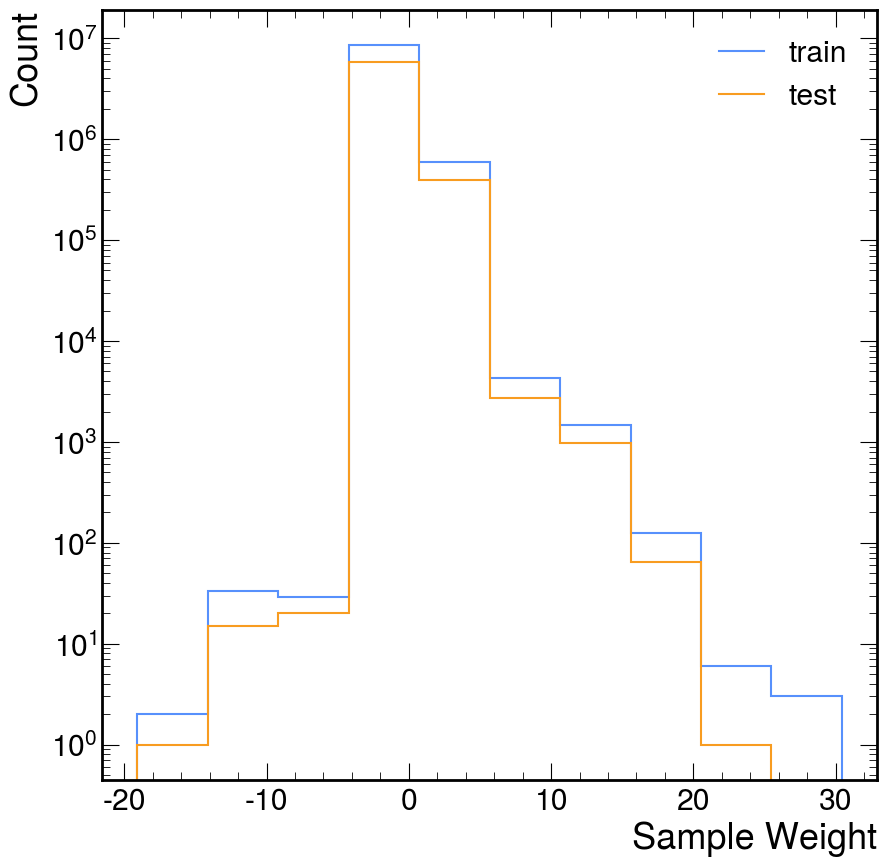

In [26]:
htrain, bins = np.histogram(sample_weights_train)
htest, binstest = np.histogram(sample_weights_test, bins=bins)
fig, ax = plt.subplots()
hep.histplot(htrain, bins, label="train")
hep.histplot(htest, bins, label='test')
ax.set_yscale('log')
ax.set_xlabel("Sample Weight")
ax.set_ylabel("Count")
ax.legend()
plt.savefig(plot_dir + "Weights.png")
plt.savefig(plot_dir + "Weights.pdf")
plt.show()

In [27]:
print("-inf position (by index):", np.isneginf(x_train)[np.isneginf(x_train)])
print("inf position (by index):", np.isinf(x_train)[np.isinf(x_train)])
print("nan position (by index):", np.isnan(x_train)[np.isnan(x_train)])
x_train[np.isneginf(x_train)] = np.nan
x_train[np.isinf(x_train)] = np.nan
x_train[np.isnan(x_train)] = 0.0

-inf position (by index): []
inf position (by index): []
nan position (by index): [ True  True  True ...  True  True  True]


In [28]:
mean_map = {}
std_map = {}
#for i, var in enumerate(variables[:-3]):
for i, var in enumerate(variables[:-3]):
    print("standarizing : ", var[0])
    print("Iterator : ", i)
    null_value = 0
    if var[0] in ["delta_phi_diJet", "pt_balance"]:
        null_value = -1

    mask_train = x_train[:, i] != null_value
    mask_test = x_test[:, i] != null_value
    mean_map[var[0]] = x_train[mask_train, i].mean()
    std_map[var[0]] = x_train[mask_train, i].std()
    print("[Info]: Train Sample Mean: ", mean_map[var[0]])
    print("[Info]: Train Sample std: ", std_map[var[0]])
    
    h_pre_train, binspre = np.histogram(x_train[mask_train, i])
    h_pre_test, bins = np.histogram(x_test[mask_test, i], bins=binspre)
    fig, ax = plt.subplots()
    hep.histplot(h_pre_train, binspre, label="train")
    hep.histplot(h_pre_test, binspre, label="test")
    #ax.set_yscale('log')
    ax.set_xlabel(var[0])
    ax.set_ylabel("Count")
    ax.legend()
    plt.title("Pre standardization")
    plt.savefig(plot_dir + var[0] + "_prestd")
    #plt.show()
    plt.close()
    
    x_train[mask_train, i] = (x_train[mask_train, i] - mean_map[var[0]]) / std_map[
        var[0]
    ]
    x_test[mask_test, i] = (x_test[mask_test, i] - mean_map[var[0]]) / std_map[
        var[0]
    ]
    
    h_post_train, binspost = np.histogram(x_train[mask_train, i])
    h_post_test, bins = np.histogram(x_test[mask_test, i], bins=binspost)
    fig, ax = plt.subplots()
    hep.histplot(h_post_train, binspost, label="train")
    hep.histplot(h_post_test, binspost, label="test")
    #ax.set_yscale('log')
    ax.set_xlabel(var[0])
    ax.set_ylabel("Count")
    ax.legend()
    plt.title("Post standardization")
    plt.savefig(plot_dir + var[0] + "_poststd")
    #plt.show()
    plt.close()
    
    #break

standarizing :  diMuon_rapidity
Iterator :  0
[Info]: Train Sample Mean:  2.3076269134238456e-05
[Info]: Train Sample std:  1.0666860048636733
standarizing :  mu1_eta
Iterator :  1
[Info]: Train Sample Mean:  0.0006612661838317362
[Info]: Train Sample std:  1.2300936077933378
standarizing :  mu2_eta
Iterator :  2
[Info]: Train Sample Mean:  -2.9006422426479043e-05
[Info]: Train Sample std:  1.2435467951741508
standarizing :  phi_CS
Iterator :  3
[Info]: Train Sample Mean:  0.00043730648982707933
[Info]: Train Sample std:  1.8060073991296586
standarizing :  cos_theta_CS
Iterator :  4
[Info]: Train Sample Mean:  -0.00022280597389783027
[Info]: Train Sample std:  0.5259373432462395
standarizing :  n_jet
Iterator :  5
[Info]: Train Sample Mean:  1.483572180598311
[Info]: Train Sample std:  0.8339316361250767
standarizing :  leading_jet_pt
Iterator :  6
[Info]: Train Sample Mean:  67.87461486571344
[Info]: Train Sample std:  54.218634427646
standarizing :  leading_jet_eta
Iterator :  7
[Inf

In [29]:
w_train = np.absolute(sample_weights_train) / np.array(x_train_p[:, -2])
w_test = np.absolute(sample_weights_test) / np.array(x_test_p[:, -2])

In [30]:
def compute_significance(y_true, y_score, weights):

    thresholds = np.linspace(0, 1, 100)
    best_Z = 0

    for cut in thresholds:
        passed = y_score > cut

        S = np.sum(weights[(y_true == 1) & passed])
        B = np.sum(weights[(y_true == 0) & passed])
        print("Signal events:" + str(S))
        print("BKG events:" + str(B))

        if B > 0:
            Z = S / np.sqrt(B)
        else:
            Z = 0

        if Z > best_Z:
            best_Z = Z

    return best_Z

In [53]:
def objective(trial):

    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 5),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "n_estimators": 2000,
        "device": "cuda",

        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),

        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 1.0, log=True),

        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "n_jobs": 4,
        "verbosity": 0,
        "early_stopping_rounds": 50,
    }

    model = xgb.XGBClassifier(**params)

    model.fit(
        x_train,
        y_train,
        sample_weight=w_train,
        eval_set=[(x_train, y_train), (x_test, y_test)],
        sample_weight_eval_set=[w_train, w_test],
        verbose=False,
    )

    y_pred = model.predict_proba(x_test)[:, 1]
    
    #Z = compute_significance(y_test, y_pred, w_test)

    auc = roc_auc_score(
        y_test,
        y_pred,
        sample_weight=w_test,
    )

    return auc

In [54]:
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=100)

print("Best AUC:", study.best_value)
print("Best parameters:")
print(study.best_params)

[I 2026-05-22 20:00:27,620] A new study created in memory with name: no-name-482a5b58-aa19-4fe8-8fb2-98080c4e63f1
[I 2026-05-22 20:02:31,240] Trial 0 finished with value: 0.7012318565517918 and parameters: {'max_depth': 4, 'learning_rate': 0.10380715308622233, 'min_child_weight': 3.297239345633392, 'subsample': 0.9817214588799544, 'colsample_bytree': 0.8685954757336247, 'reg_lambda': 1.677671342368056, 'reg_alpha': 0.7197613289109381}. Best is trial 0 with value: 0.7012318565517918.
[I 2026-05-22 20:04:50,187] Trial 1 finished with value: 0.7018191381250656 and parameters: {'max_depth': 5, 'learning_rate': 0.07625497154397824, 'min_child_weight': 1.151425209983858, 'subsample': 0.8746517521207046, 'colsample_bytree': 0.8180770416969748, 'reg_lambda': 0.23761059634406745, 'reg_alpha': 0.23759334586446426}. Best is trial 1 with value: 0.7018191381250656.
[I 2026-05-22 20:06:24,781] Trial 2 finished with value: 0.6903142970385721 and parameters: {'max_depth': 2, 'learning_rate': 0.0145892

Best AUC: 0.7039522872099662
Best parameters:
{'max_depth': 5, 'learning_rate': 0.162477112271678, 'min_child_weight': 16.53177169635598, 'subsample': 0.8794844971111483, 'colsample_bytree': 0.8979705863288135, 'reg_lambda': 0.12062645684007227, 'reg_alpha': 0.052012191742071404}


In [55]:
fig = vis.plot_optimization_history(study)
show(fig)

fig = vis.plot_param_importances(study)
show(fig)

fig = vis.plot_slice(
    study,
    params=[
        "max_depth",
        "learning_rate",
        "min_child_weight",
        "subsample",
        "colsample_bytree",
        "reg_lambda",
        "reg_alpha",
    ],
)
show(fig)

In [56]:
best_params = study.best_params

final_model = xgb.XGBClassifier(
    **best_params,
    n_estimators=2000,
    #objective="binary:logistic",
    eval_metric="logloss",
    early_stopping_rounds=50,
    n_jobs=4,
    verbosity=1,
)

final_model.fit(
    x_train,
    y_train,
    sample_weight=w_train,
    eval_set=[(x_test, y_test)],
    sample_weight_eval_set=[w_test],
    verbose=False,
)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8979705863288135
,device,None
,early_stopping_rounds,50
,enable_categorical,False
,eval_metric,'logloss'
